# DEL 1 :Grundlägande analys och statistik

## 1. Import och datainläsning

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [9]:
df = pd.read_csv("../data/health_study_dataset (1).csv")

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [17]:
display(df.head(3))
display(df.tail(3))

print(f"Datasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")

print(f"\n{"Kolumnamn": <20} Datatype:")
for column in df.columns:
    print(f" - {column: <15} : {df[column].dtype}")

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0


Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering och datarensning

In [49]:
expected_values = ({df.columns[0]: df["id"].is_unique,
                    df.columns[2]: df["sex"].isin(["M", "F"]).all(),
                    df.columns[7]: df["smoker"].isin(["No", "Yes"]).all(),
                    df.columns[8]: df["disease"].isin([0, 1]).all(),
                    })
display(pd.DataFrame(expected_values, index=["Validering"]).replace({True: "Korrekt", False: "Fel"}))

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

In [42]:

display(df.isna().sum().to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


### 2.2.2. Validation of datatyper i datasetet

In [ ]:
expected_types = {
    "id": "int", 
    "age": "int", 
    "sex": "str", 
    "height": "float",
    "weight": "float",
    "systolic_bp": "float",
    "cholesterol": "float",
    "smoker": "str",
    "disease": "int"
    }


correct_columns = []
incorrect_columns = []


for column in df.columns:
    expected_type = expected_types[column]
    passed = True
    
    for value in df[column]:
        actual_type = type(value).__name__
        if actual_type != expected_type:
            passed = False
    if passed:
        correct_columns.append(column)
    else:
        incorrect_columns.append(column)

result = {column: "Korrekt" if column in correct_columns else "Fel" for column in df.columns}

display(pd.DataFrame(result, index=["Datatyp validering"]))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [89]:
analysis_value = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(["mean", "median", "min", "max"])

display(analysis_value.round(2))

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### 3.2. Visualisering

### 3.2.1 Histogram över systoliskt blodtryck

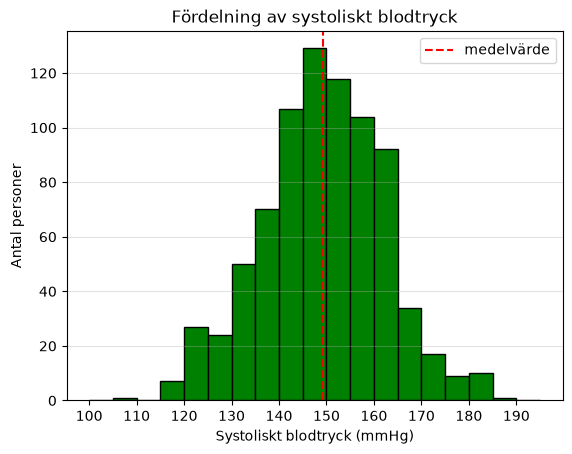

In [112]:
plt.hist(df["systolic_bp"], bins=np.arange(100, 200, 5), edgecolor="black", color="green")
plt.xticks(np.arange(100, 200, 10))
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal personer")

plt.axvline(df["systolic_bp"].mean(),
            color="red",
            linestyle="--", 
            label="medelvärde")
plt.grid(axis="y", alpha=0.35)
plt.legend()
plt.show()

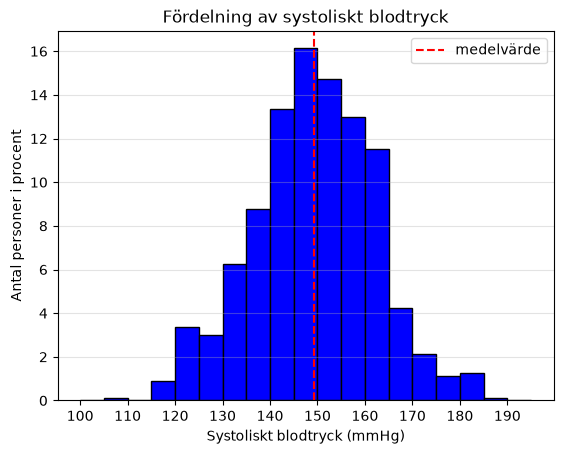

In [113]:
plt.hist(df["systolic_bp"], weights=np.ones_like(df["systolic_bp"])*100 / len(df["systolic_bp"]), bins=np.arange(100, 200, 5), edgecolor="black", color="blue")
plt.xticks(np.arange(100, 200, 10))
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal personer i procent")

plt.axvline(df["systolic_bp"].mean(),
            color="red",
            linestyle="--", 
            label="medelvärde")
plt.grid(axis="y", alpha=0.35)
plt.legend()
plt.show()

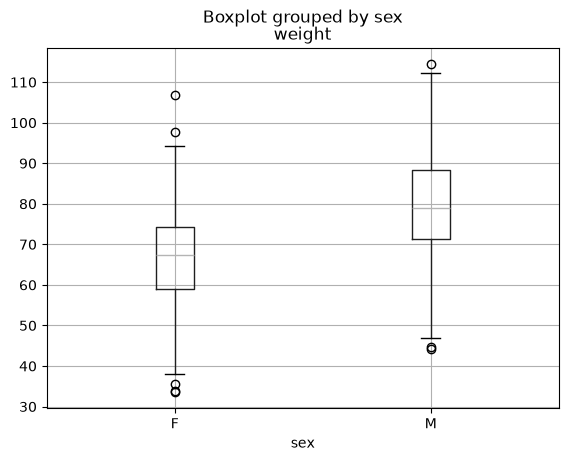

In [115]:
df.boxplot(column="weight", by="sex")
plt.show()

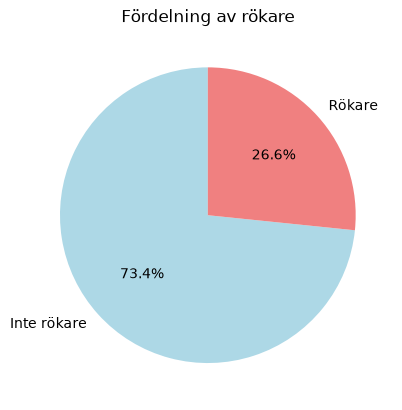

In [119]:
plt.pie(df["smoker"].value_counts(), labels=["Inte rökare", "Rökare"], autopct="%1.1f%%", startangle=90, colors=["lightblue", "lightcoral"])
plt.title("Fördelning av rökare")
plt.show()

In [133]:
grouped = df.groupby("sex")
counted_smokers = pd.DataFrame(data).T
data ={}
for sex, groupp in grouped:
    total = len(groupp)

    smoker_count = groupp["smoker"].value_counts()

    data[sex] = smoker_count

    print(sex)
    print(smoker_count)

procent_smokers = pd.DataFrame(data).T
data_procent ={}
for sex, groupp in grouped:
    total = len(groupp)

    smoker_count = groupp["smoker"].value_counts()*100/total 
    
    data_procent[sex] = smoker_count

    print(sex)
    print(smoker_count)

procent_smokers = pd.DataFrame(data_procent).T


F
smoker
No     287
Yes    116
Name: count, dtype: int64
M
smoker
No     300
Yes     97
Name: count, dtype: int64
F
smoker
No     71.215881
Yes    28.784119
Name: count, dtype: float64
M
smoker
No     75.566751
Yes    24.433249
Name: count, dtype: float64


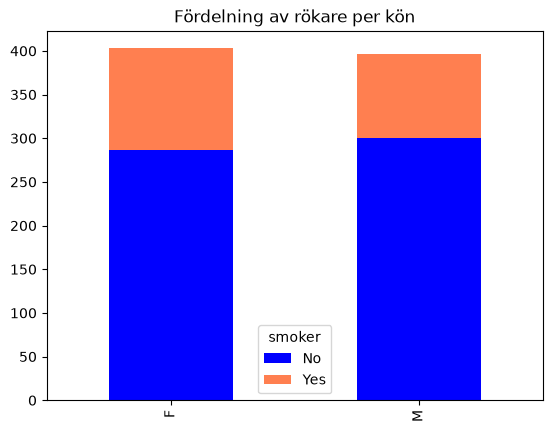

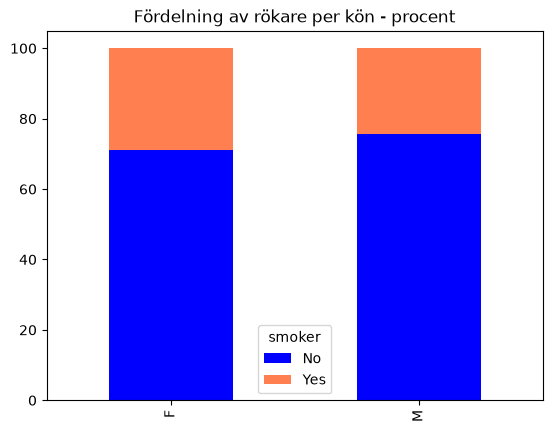

In [134]:
counted_smokers.plot(kind="bar", stacked=True, color=["blue", "coral"])
plt.title("Fördelning av rökare per kön")
plt.show()

procent_smokers.plot(kind="bar", stacked=True, color=["blue", "coral"])
plt.title("Fördelning av rökare per kön - procent")
plt.show()

## 4. Simulering kopplad till caset

## 5. Konfidensintervall

## 6. Hypotesprövning